In [2]:
import pandas as pd 

import numpy as np 

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_sample_weight

In [ ]:
data = pd.read_csv('Pv_loc_train.csv')
data = data.set_index('Sample')

target = data.loc[:, 'Continent']
target = target.replace({'SE_Asia':0, 'America':1, 'Asia':10, 'Africa':11}).astype(int) 
data_predictors = data.loc[:, data.columns != 'Continent']
predictor_names = data_predictors.columns

In [3]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tot_importances = []      

for train_rows, held_out_rows in folds.split(data_predictors, target):
    X_fold = data_predictors.iloc[train_rows]
    y_fold = target.iloc[train_rows]
    
    weights = compute_sample_weight("balanced", y_fold) 

    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, subsample=0.75, max_features=0.25, random_state=42)
    
    gb.fit(X_fold, y_fold, sample_weight= weights)

    tot_importances.append(gb.feature_importances_)

tot_importances = np.array(tot_importances)

In [4]:
import_tab = pd.DataFrame(tot_importances)
import_tab.columns= predictor_names
import_tra = import_tab.transpose()
import_tra['Importance'] = import_tra.mean(axis=1)
import_tra.head()
import_sort = import_tra.sort_values(by='Importance', ascending = False)
import_sort.head()

,0,1,2,3,4,Importance
PKNH_05_v2 732015,0.095355,0.096611,0.095892,0.095409,0.000000,0.076653
PKNH_11_v2 1041498,0.042753,0.042499,0.000000,0.042644,0.096116,0.044802
PKNH_14_v2 2812021,0.070150,0.000000,0.070783,0.000002,0.000000,0.028187
PKNH_09_v2 1548167,0.000000,0.070163,0.000000,0.070513,0.000000,0.028135
PKNH_14_v2 402185,0.000008,0.107868,0.000000,0.000000,0.000000,0.021575


In [5]:
barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

for item in barcode_lengths: 
    feat_vals = import_sort.iloc[:item,]
    feat_names = feat_vals.index.tolist()

    with open(f"GB_subsets/top_{item}_GB.txt", "w") as f:
            f.write("\n".join(feat_names))

In [ ]:
feat_hun = import_sort.iloc[:100,]

feat_hun_imp = feat_hun['Importance']

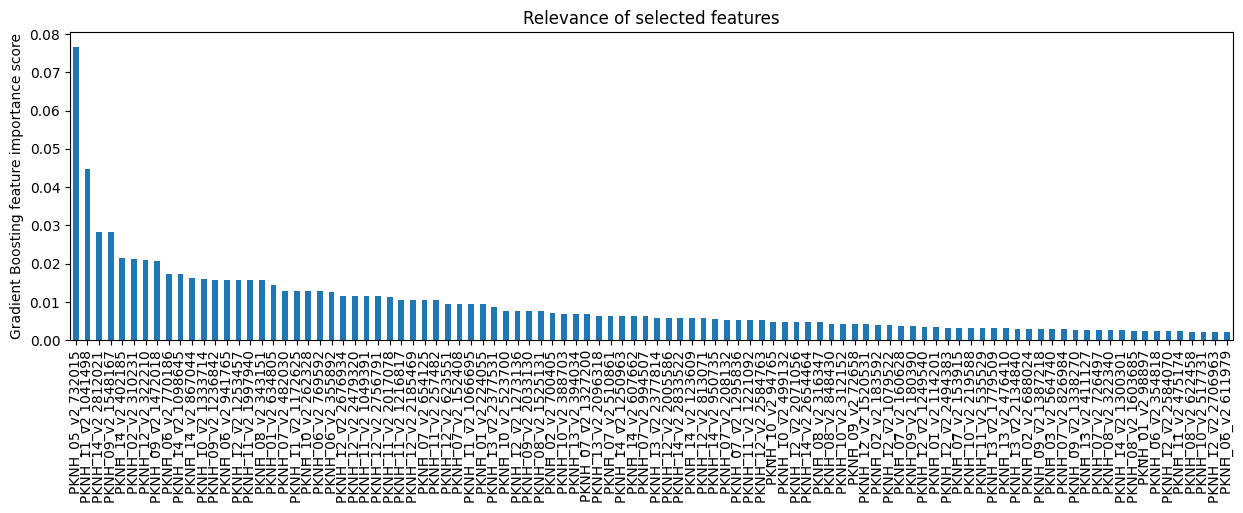

In [9]:
feat_hun_imp.plot.bar(figsize=(15, 4))
plt.title("Relevance of selected features")
plt.ylabel("Gradient Boosting feature importance score")
plt.savefig('GB_subsets/GB_feat_importance.png')